# Ujian Analitik Teks: Klasifikasi Sentimen Tweet

**Nama:** Ananda Ramadhani  
**NIM:** 25917042  
**Repositori GitHub:** https://github.com/Ramadhaniananda22/25917042---Ananda-Ramadhani---UTS-Analitik-Teks

Alur pengerjaannya:

| Bagian | Isi |
|---|---|
| 0 | Identifikasi masalah dan rancangan solusi |
| 1 | Pengumpulan data |
| 2 | Pra-pemrosesan teks |
| 3 | Rekayasa fitur (TF-IDF dan Word2Vec) |
| 4 | Analisis data eksploratif dan visualisasi |
| 5 | Klasifikasi teks |
| 6 | Soal teori |

## Bagian 0: Identifikasi Masalah

**Artikel yang dipakai:** Zhao, J., & Gui, X. (2017). *Comparison Research on Text Pre-processing Methods on Twitter Sentiment Analysis*. IEEE Access, 5, 2870–2879. DOI: [10.1109/ACCESS.2017.2672677](https://doi.org/10.1109/ACCESS.2017.2672677). Berkas PDF artikel dilampirkan di repositori GitHub.

**Masalah yang diangkat.** Media sosial seperti Twitter dipakai organisasi untuk memantau pendapat publik tentang produk dan peristiwa secara langsung. Masalahnya, tweet itu pendek, tidak baku, dan banyak berisi singkatan, URL, serta mention, sehingga menentukan sentimennya secara otomatis tidak mudah. Artikel tersebut menunjukkan bahwa langkah pra-pemrosesan teks ikut menentukan kualitas klasifikasi sentimen, tetapi sering kurang diperhatikan.

**Rancangan solusi.** Masalah ini dirumuskan sebagai **klasifikasi teks multikelas**: setiap tweet dipetakan ke salah satu dari empat label (*Positive*, *Negative*, *Neutral*, *Irrelevant*). Tahapannya:

1. **Pengumpulan data:** dataset *Twitter Entity Sentiment Analysis* (berisi tweet berlabel sentimen).
2. **Pra-pemrosesan:** lowercasing, penghapusan URL, mention, tanda baca dan karakter khusus, tokenisasi, penghapusan stopwords, dan stemming.
3. **Rekayasa fitur:** TF-IDF sebagai fitur untuk model, dan Word2Vec untuk melihat kedekatan makna antarkata.
4. **Analisis eksploratif:** word cloud, distribusi panjang teks, dan frekuensi kata teratas.
5. **Klasifikasi:** Naive Bayes, Logistic Regression, dan SVM, dievaluasi dengan accuracy, precision, recall, dan F1.

### Persiapan lingkungan

Sel berikut memasang pustaka yang dibutuhkan (di Google Colab biasanya sudah terpasang, jadi sel ini hanya memastikan) lalu mengimpor semua pustaka yang dipakai di seluruh notebook.

In [27]:
# Memastikan pustaka tambahan terpasang (aman dijalankan ulang)
%pip install -q nltk gensim wordcloud

In [28]:
# Impor pustaka yang dipakai di seluruh notebook
import re
import os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

# Unduh resource NLTK (tokenizer dan daftar stopwords)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

sns.set_theme(style='whitegrid')   # gaya default semua grafik

## Bagian 1: Pengumpulan Data

### 1.1 Deskripsi dataset

- **Sumber:** *Twitter Entity Sentiment Analysis*, dataset publik dari Kaggle. Berkas yang dipakai adalah `twitter_training.csv`, dan berkas ini dilampirkan di repositori GitHub.
- **Isi:** tweet berbahasa Inggris tentang berbagai entitas (misalnya nama game, perusahaan, dan produk), masing-masing sudah diberi label sentimen.
- **Jumlah sampel mentah:** 74.682 baris.
- **Fitur (4 kolom, berkas tidak memiliki header):**

| Kolom | Keterangan |
|---|---|
| `id` | nomor identitas tweet/entitas |
| `entity` | entitas yang dibicarakan (mis. Borderlands, Facebook) |
| `label` | label sentimen: Positive, Negative, Neutral, Irrelevant |
| `text` | isi tweet |

Berkas validasi (`twitter_validation.csv`) **tidak dipakai**. Pembagian data latih dan uji dilakukan sendiri pada Bagian 5.

### 1.2 Kode pengumpulan data

In [29]:
# Cari berkas dataset: di folder data/ (struktur repositori) atau di folder kerja
kandidat = ['data/twitter_training.csv', 'twitter_training.csv']
DATA_PATH = next((p for p in kandidat if os.path.exists(p)), None)

if DATA_PATH is None:
    # Jika belum ada (mis. di Colab), tampilkan dialog unggah
    from google.colab import files
    files.upload()
    DATA_PATH = 'twitter_training.csv'

# Berkas tidak punya header, jadi nama kolom ditentukan sendiri
cols = ['id', 'entity', 'label', 'text']
df = pd.read_csv(DATA_PATH, header=None, names=cols)
print("Jumlah baris mentah:", len(df))
df.head()

Jumlah baris mentah: 74682


,id,entity,label,text
0,2401,Borderlands,Positive,"im getting on borderlands and i will murder you all ,"
1,2401,Borderlands,Positive,"I am coming to the borders and I will kill you all,"
2,2401,Borderlands,Positive,"im getting on borderlands and i will kill you all,"
3,2401,Borderlands,Positive,"im coming on borderlands and i will murder you all,"
4,2401,Borderlands,Positive,"im getting on borderlands 2 and i will murder you me all,"


In [30]:
# Pembersihan dasar: buang teks kosong dan teks duplikat.
# Duplikat dibuang agar tweet yang sama tidak muncul di data latih sekaligus data uji.
n_awal = len(df)
df = df.dropna(subset=['text'])
df = df.drop_duplicates(subset=['text']).reset_index(drop=True)
print(f"Baris sebelum dibersihkan: {n_awal}")
print(f"Baris sesudah dibersihkan: {len(df)}")

Baris sebelum dibersihkan: 74682
Baris sesudah dibersihkan: 69491


In [31]:
# Ringkasan dataset: tipe kolom, distribusi label, dan jumlah entitas
df.info()
print()
print("Distribusi label:")
print(df['label'].value_counts())
print()
print("Jumlah entitas berbeda:", df['entity'].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69491 entries, 0 to 69490
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      69491 non-null  int64 
 1   entity  69491 non-null  object
 2   label   69491 non-null  object
 3   text    69491 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.1+ MB

Distribusi label:
label
Negative      21166
Positive      19067
Neutral       17042
Irrelevant    12216
Name: count, dtype: int64

Jumlah entitas berbeda: 32


**Ringkasan.** Angka jumlah sampel setelah dibersihkan, distribusi keempat label, dan jumlah entitas dapat dibaca pada output sel di atas. Data kelas cukup seimbang sehingga tidak perlu penyeimbangan khusus.

## Bagian 2: Pra-pemrosesan Teks

Tweet mentah memuat URL, mention (`@nama`), angka, emoji, dan huruf kapital campuran yang membuat kata yang sama dianggap berbeda. Pra-pemrosesan dilakukan dengan urutan berikut:

1. **Lowercasing:** semua huruf diubah menjadi huruf kecil.
2. **Penghapusan URL, mention, tanda baca, angka, dan karakter khusus** dengan regular expression.
3. **Tokenisasi:** teks dipecah menjadi daftar kata (token) dengan `word_tokenize` dari NLTK.
4. **Penghapusan stopwords:** kata umum yang kurang bermakna (*the, is, and, ...*) dibuang memakai daftar stopwords bahasa Inggris dari NLTK.
5. **Stemming:** kata dikembalikan ke bentuk dasarnya dengan `PorterStemmer` (mis. *playing*, *played* menjadi *play*).

In [32]:
stop_words = set(stopwords.words('english'))   # daftar stopwords bahasa Inggris
stemmer = PorterStemmer()
stem_cache = {}                                # cache agar kata yang sama tidak di-stem berulang

def stem(word):
    # Stemming dengan cache supaya proses 70 ribuan tweet lebih cepat
    if word not in stem_cache:
        stem_cache[word] = stemmer.stem(word)
    return stem_cache[word]

def preprocess(text):
    # Pipeline pra-pemrosesan satu tweet, mengembalikan daftar token bersih
    text = text.lower()                              # d. lowercasing
    text = re.sub(r'http\S+|www\.\S+|pic\.twitter\.com\s*/?\s*\S*|\S+\.com\S*', ' ', text)    # hapus URL (termasuk pic.twitter.com dan alamat .com)
    text = re.sub(r'@\w+', ' ', text)                # hapus mention
    text = re.sub(r'[^a-z\s]', ' ', text)            # e. hapus tanda baca, angka, emoji, karakter khusus
    tokens = word_tokenize(text)                     # a. tokenisasi
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]  # b. hapus stopwords
    return [stem(t) for t in tokens]                 # c. stemming

### Contoh langkah demi langkah pada satu tweet

In [33]:
# Memperlihatkan hasil tiap tahap pada satu contoh tweet
contoh = df['text'][3]
print("0. Teks asli          :", contoh)

t1 = contoh.lower()
print("1. Lowercasing        :", t1)

t2 = re.sub(r'http\S+|www\.\S+|pic\.twitter\.com\s*/?\s*\S*|\S+\.com\S*', ' ', t1)
t2 = re.sub(r'@\w+', ' ', t2)
t2 = re.sub(r'[^a-z\s]', ' ', t2)
print("2. Hapus tanda baca   :", t2)

t3 = word_tokenize(t2)
print("3. Tokenisasi         :", t3)

t4 = [t for t in t3 if t not in stop_words and len(t) > 1]
print("4. Hapus stopwords    :", t4)

t5 = [stem(t) for t in t4]
print("5. Stemming           :", t5)

0. Teks asli          : im coming on borderlands and i will murder you all,
1. Lowercasing        : im coming on borderlands and i will murder you all,
2. Hapus tanda baca   : im coming on borderlands and i will murder you all 
3. Tokenisasi         : ['im', 'coming', 'on', 'borderlands', 'and', 'i', 'will', 'murder', 'you', 'all']
4. Hapus stopwords    : ['im', 'coming', 'borderlands', 'murder']
5. Stemming           : ['im', 'come', 'borderland', 'murder']


In [34]:
# Terapkan pra-pemrosesan ke seluruh data (butuh beberapa menit untuk data besar)
df['tokens'] = df['text'].apply(preprocess)
df['clean_text'] = df['tokens'].apply(lambda x: ' '.join(x))

# Buang tweet yang kosong setelah pra-pemrosesan (isinya hanya stopwords/URL)
n_sebelum = len(df)
df = df[df['clean_text'].str.len() > 0].reset_index(drop=True)
print(f"Tweet kosong setelah pra-pemrosesan dibuang: {n_sebelum - len(df)}")
print("Jumlah data akhir:", len(df))

Tweet kosong setelah pra-pemrosesan dibuang: 487
Jumlah data akhir: 69004


In [35]:
# Contoh teks sebelum dan sesudah pra-pemrosesan
pd.set_option('display.max_colwidth', 120)
df[['text', 'clean_text']].head(8)

,text,clean_text
0,"im getting on borderlands and i will murder you all ,",im get borderland murder
1,"I am coming to the borders and I will kill you all,",come border kill
2,"im getting on borderlands and i will kill you all,",im get borderland kill
3,"im coming on borderlands and i will murder you all,",im come borderland murder
4,"im getting on borderlands 2 and i will murder you me all,",im get borderland murder
5,"im getting into borderlands and i can murder you all,",im get borderland murder
6,So I spent a few hours making something for fun. . . If you don't know I am a HUGE @Borderlands fan and Maya is one ...,spent hour make someth fun know huge fan maya one favorit charact decid make wallpap pc origin imag versu creation m...
7,So I spent a couple of hours doing something for fun... If you don't know that I'm a huge @ Borderlands fan and Maya...,spent coupl hour someth fun know huge borderland fan maya one favorit charact decid make wallpap pc origin pictur co...


## Bagian 3: Rekayasa Fitur

Model pembelajaran mesin tidak bisa membaca teks secara langsung, sehingga teks perlu diubah menjadi angka (vektor). Dua teknik dipakai di sini.

### 3.1 TF-IDF (Term Frequency-Inverse Document Frequency)

**Konsep.** TF-IDF memberi bobot pada setiap kata di setiap dokumen berdasarkan dua hal:

- **TF (Term Frequency):** seberapa sering kata muncul di satu dokumen. Makin sering, makin penting bagi dokumen itu.
- **IDF (Inverse Document Frequency):** seberapa jarang kata muncul di seluruh dokumen. Kata yang ada di hampir semua dokumen (kata umum) mendapat bobot kecil, sedangkan kata yang khas mendapat bobot besar.

$$\text{TF-IDF}(t, d) = \text{TF}(t, d) \times \text{IDF}(t), \qquad \text{IDF}(t) = \log \frac{N}{\text{df}(t)}$$

dengan $N$ jumlah dokumen dan $\text{df}(t)$ jumlah dokumen yang memuat kata $t$ (implementasi scikit-learn memakai versi yang diperhalus dan menormalkan tiap vektor). Hasilnya berupa matriks dokumen × kata. Matriks inilah yang dipakai sebagai masukan classifier di Bagian 5.

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Batasi 5000 kata dengan frekuensi tertinggi agar matriks tidak terlalu besar
tfidf = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf.fit_transform(df['clean_text'])

print("Ukuran matriks TF-IDF (dokumen x kata):", X_tfidf.shape)
print("Contoh 15 kata dalam kosakata:", list(tfidf.get_feature_names_out()[:15]))

Ukuran matriks TF-IDF (dokumen x kata): (69004, 5000)
Contoh 15 kata dalam kosakata: ['aa', 'aaa', 'aaron', 'ab', 'abandon', 'abc', 'abella', 'abil', 'abl', 'aboard', 'absenc', 'absolut', 'absurd', 'abt', 'abus']


In [37]:
# Lihat kata dengan bobot TF-IDF tertinggi pada satu dokumen
i = 0
terms = tfidf.get_feature_names_out()
row = X_tfidf[i].toarray().ravel()
top_idx = row.argsort()[::-1][:5]

print("Teks bersih :", df['clean_text'][i])
print("Kata berbobot tertinggi:")
for j in top_idx:
    if row[j] > 0:
        print(f"  {terms[j]:<12} {row[j]:.3f}")

Teks bersih : im get borderland murder
Kata berbobot tertinggi:
  murder       0.670
  im           0.504
  borderland   0.441
  get          0.321


### 3.2 Word2Vec

**Konsep.** Word2Vec mengubah setiap kata menjadi vektor padat (di sini 100 dimensi) lewat jaringan saraf dangkal yang dilatih untuk memprediksi kata dari konteksnya (atau sebaliknya). Akibatnya kata yang sering muncul dalam konteks serupa memiliki vektor yang berdekatan. Berbeda dengan TF-IDF yang hanya menghitung kemunculan kata, Word2Vec menangkap **kemiripan makna** antarkata.

In [38]:
from gensim.models import Word2Vec

# Latih Word2Vec dari token hasil pra-pemrosesan
# vector_size: dimensi vektor, window: jarak konteks, min_count: abaikan kata yang terlalu jarang
w2v = Word2Vec(sentences=df['tokens'].tolist(), vector_size=100, window=5,
               min_count=5, workers=4, seed=0)

print("Ukuran kosakata Word2Vec:", len(w2v.wv))

Ukuran kosakata Word2Vec: 11092


In [39]:
# Contoh vektor satu kata dan kata-kata yang paling mirip dengannya
kata_uji = [k for k in ['game', 'love', 'good', 'bad'] if k in w2v.wv]

print(f"Vektor untuk '{kata_uji[0]}' (5 dimensi pertama):", w2v.wv[kata_uji[0]][:5])
print()
for k in kata_uji:
    mirip = [(w, round(s, 3)) for w, s in w2v.wv.most_similar(k, topn=5)]
    print(f"Kata mirip '{k}':", mirip)

Vektor untuk 'game' (5 dimensi pertama): [-0.57300985  1.4971218  -0.5235468  -0.76591855 -1.2065836 ]

Kata mirip 'game': [('madden', 0.809), ('fp', 0.752), ('six', 0.726), ('titl', 0.713), ('almost', 0.692)]
Kata mirip 'love': [('enjoy', 0.708), ('amaz', 0.683), ('shoo', 0.68), ('builder', 0.654), ('fun', 0.651)]
Kata mirip 'good': [('uncertain', 0.733), ('satisfi', 0.727), ('nice', 0.719), ('bad', 0.713), ('sad', 0.706)]
Kata mirip 'bad': [('sad', 0.831), ('like', 0.825), ('stingi', 0.798), ('sometim', 0.778), ('crazi', 0.774)]


## Bagian 4: Analisis Data Eksploratif dan Visualisasi

### 4.1 Word cloud
Word cloud menampilkan kata yang paling sering muncul: makin besar ukuran kata, makin sering kata itu muncul. Kata yang tampil adalah bentuk hasil stemming.

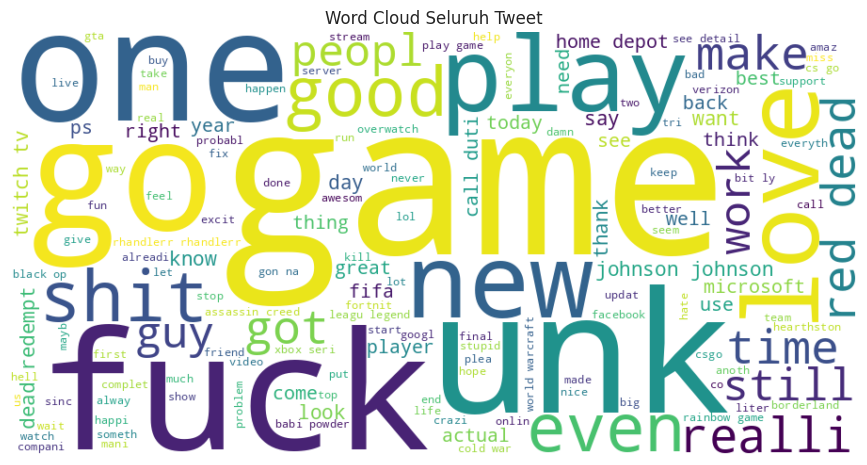

In [40]:
from wordcloud import WordCloud

# Gabungkan seluruh teks bersih menjadi satu string lalu buat word cloud
semua_kata = ' '.join(df['clean_text'])
wc = WordCloud(width=900, height=450, background_color='white',
               max_words=150, random_state=0).generate(semua_kata)

plt.figure(figsize=(11, 5.5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud Seluruh Tweet')
plt.show()

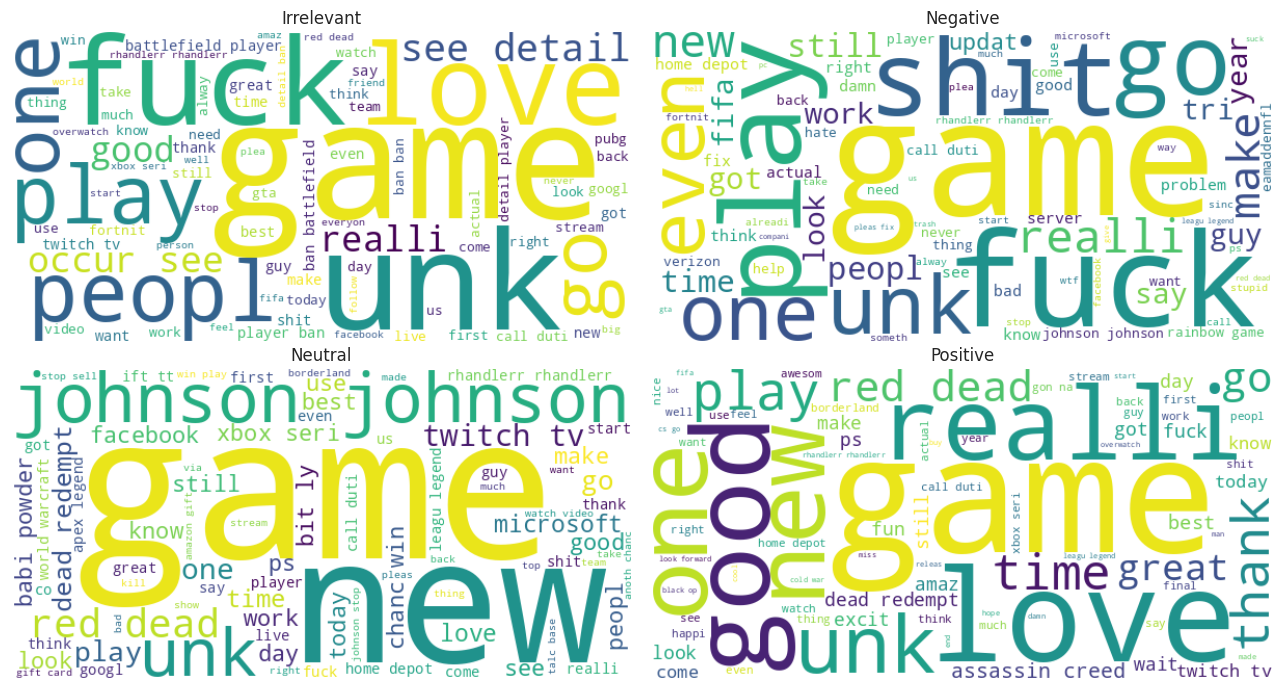

In [41]:
# Word cloud per kelas sentimen untuk membandingkan kata dominan tiap kelas
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, lab in zip(axes.ravel(), sorted(df['label'].unique())):
    teks = ' '.join(df.loc[df['label'] == lab, 'clean_text'])
    ax.imshow(WordCloud(width=600, height=300, background_color='white',
                        max_words=80, random_state=0).generate(teks), interpolation='bilinear')
    ax.set_title(lab)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 4.2 Distribusi panjang teks
Panjang teks diukur dari jumlah kata per dokumen setelah pra-pemrosesan.

count    69004.000000
mean        10.681845
std          7.326347
min          1.000000
25%          5.000000
50%          9.000000
75%         15.000000
max        130.000000
Name: n_words, dtype: float64


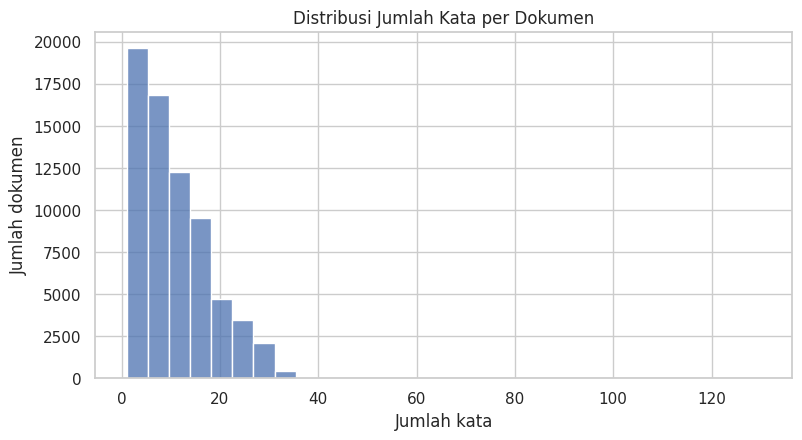

In [42]:
# Hitung jumlah kata per dokumen
df['n_words'] = df['tokens'].apply(len)
print(df['n_words'].describe())

plt.figure(figsize=(9, 4.5))
sns.histplot(data=df, x='n_words', bins=30)
plt.title('Distribusi Jumlah Kata per Dokumen')
plt.xlabel('Jumlah kata')
plt.ylabel('Jumlah dokumen')
plt.show()

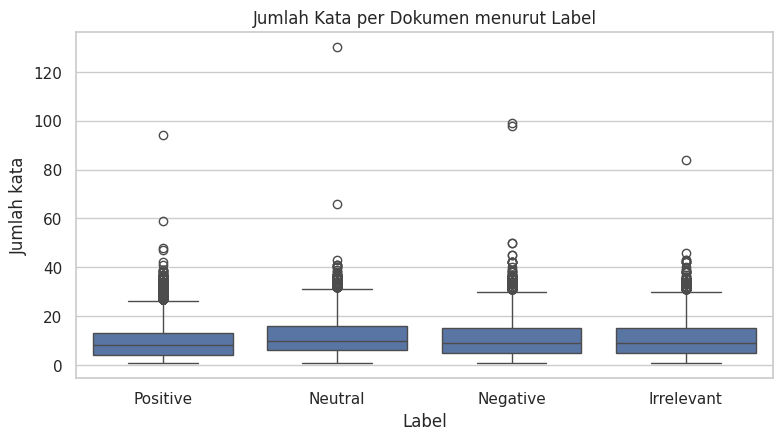

In [43]:
# Perbandingan panjang teks antar kelas sentimen
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df, x='label', y='n_words')
plt.title('Jumlah Kata per Dokumen menurut Label')
plt.xlabel('Label')
plt.ylabel('Jumlah kata')
plt.show()

### 4.3 Frekuensi kata teratas

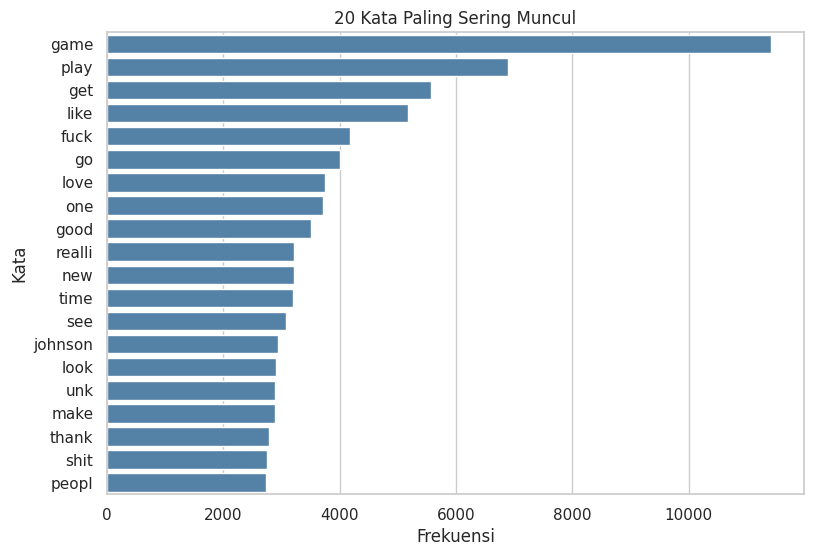

In [44]:
# Hitung frekuensi semua token lalu ambil 20 teratas
counter = Counter(w for tokens in df['tokens'] for w in tokens)
top20 = pd.DataFrame(counter.most_common(20), columns=['kata', 'frekuensi'])

plt.figure(figsize=(9, 6))
sns.barplot(data=top20, x='frekuensi', y='kata', color='steelblue')
plt.title('20 Kata Paling Sering Muncul')
plt.xlabel('Frekuensi')
plt.ylabel('Kata')
plt.show()

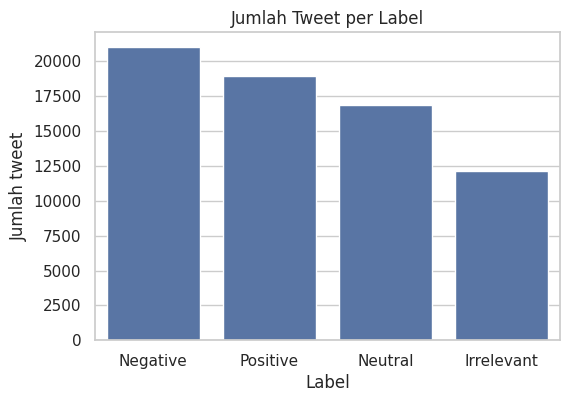

In [45]:
# Distribusi jumlah tweet per label
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='label', order=df['label'].value_counts().index)
plt.title('Jumlah Tweet per Label')
plt.xlabel('Label')
plt.ylabel('Jumlah tweet')
plt.show()

### 4.4 Ringkasan temuan EDA

Sel berikut menyusun ringkasan temuan langsung dari data, sehingga angkanya selalu cocok dengan grafik di atas.

In [46]:
# Ringkasan temuan EDA yang dihitung otomatis dari data
persen = df['label'].value_counts(normalize=True).mul(100).round(1)
rata_label = df.groupby('label')['n_words'].mean().round(1)

print("1. Kata paling sering muncul (bentuk stem):", ', '.join(top20['kata'].head(8)))
print(f"2. Rata-rata panjang tweet {df['n_words'].mean():.1f} kata (median {df['n_words'].median():.0f}, maksimum {df['n_words'].max()}), "
      "jadi tweet umumnya pendek.")
print(f"3. Rata-rata kata per label: {rata_label.to_dict()}. Label terpanjang: {rata_label.idxmax()}.")
print(f"4. Proporsi label (%): {persen.to_dict()}. Selisih kelas terbesar dan terkecil "
      f"{persen.max() - persen.min():.1f} poin persentase, jadi kelas relatif seimbang.")
for lab in sorted(df['label'].unique()):
    c = Counter(w for t in df.loc[df['label'] == lab, 'tokens'] for w in t)
    print(f"5. Kata teratas kelas {lab}:", ', '.join(w for w, _ in c.most_common(6)))

1. Kata paling sering muncul (bentuk stem): game, play, get, like, fuck, go, love, one
2. Rata-rata panjang tweet 10.7 kata (median 9, maksimum 130), jadi tweet umumnya pendek.
3. Rata-rata kata per label: {'Irrelevant': 10.7, 'Negative': 10.8, 'Neutral': 11.7, 'Positive': 9.7}. Label terpanjang: Neutral.
4. Proporsi label (%): {'Negative': 30.5, 'Positive': 27.4, 'Neutral': 24.5, 'Irrelevant': 17.6}. Selisih kelas terbesar dan terkecil 12.9 poin persentase, jadi kelas relatif seimbang.
5. Kata teratas kelas Irrelevant: game, player, like, see, ban, play
5. Kata teratas kelas Negative: game, get, fuck, play, like, shit
5. Kata teratas kelas Neutral: game, johnson, play, amazon, get, like
5. Kata teratas kelas Positive: game, play, love, good, like, thank


## Bagian 5: Klasifikasi Teks

Langkah yang dilakukan:

1. **Memisahkan** data menjadi data latih (80%) dan data uji (20%). Opsi `stratify` menjaga proporsi tiap kelas tetap sama di kedua bagian.
2. **Melatih** tiga classifier pada data latih: Multinomial Naive Bayes, Logistic Regression, dan Linear SVM, dengan fitur TF-IDF dari Bagian 3.
3. **Mengevaluasi** pada data uji dengan accuracy, precision, recall, dan F1. Karena ada empat kelas, precision, recall, dan F1 dihitung dengan rata-rata **macro** (rata-rata biasa dari keempat kelas, sehingga tiap kelas berbobot sama).

In [47]:
from sklearn.model_selection import train_test_split

# a. Pisahkan data latih dan data uji (80:20)
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=0, stratify=y
)
print("Ukuran data latih:", X_train.shape)
print("Ukuran data uji  :", X_test.shape)

Ukuran data latih: (55203, 5000)
Ukuran data uji  : (13801, 5000)


In [48]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# b. Tiga classifier yang dibandingkan
models = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Linear SVM': LinearSVC(),
}

hasil, prediksi = [], {}
for nama, model in models.items():
    model.fit(X_train, y_train)               # latih pada data latih
    pred = model.predict(X_test)              # c. prediksi pada data uji
    prediksi[nama] = pred
    hasil.append({                            # d. metrik evaluasi
        'Model': nama,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (macro)': precision_score(y_test, pred, average='macro'),
        'Recall (macro)': recall_score(y_test, pred, average='macro'),
        'F1 (macro)': f1_score(y_test, pred, average='macro'),
    })

tabel_hasil = pd.DataFrame(hasil).set_index('Model').round(4)
tabel_hasil

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Naive Bayes,0.6442,0.6592,0.6108,0.6145
Logistic Regression,0.6875,0.6825,0.6691,0.6731
Linear SVM,0.7131,0.7092,0.6977,0.7017


In [49]:
# Tentukan model terbaik berdasarkan F1 macro
terbaik = tabel_hasil['F1 (macro)'].idxmax()
print("Model terbaik berdasarkan F1 (macro):", terbaik)
print(tabel_hasil.loc[terbaik])

Model terbaik berdasarkan F1 (macro): Linear SVM
Accuracy             0.7131
Precision (macro)    0.7092
Recall (macro)       0.6977
F1 (macro)           0.7017
Name: Linear SVM, dtype: float64


Classification report - Linear SVM

              precision    recall  f1-score   support

  Irrelevant     0.6831    0.5813    0.6281      2429
    Negative     0.7287    0.7923    0.7592      4208
     Neutral     0.7192    0.6643    0.6907      3378
    Positive     0.7059    0.7530    0.7287      3786

    accuracy                         0.7131     13801
   macro avg     0.7092    0.6977    0.7017     13801
weighted avg     0.7121    0.7131    0.7110     13801



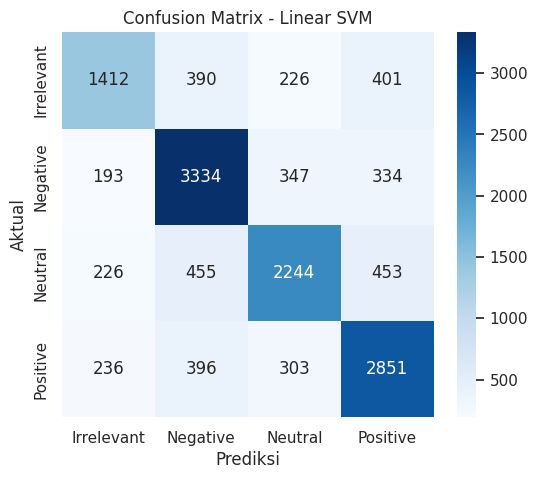

In [50]:
from sklearn.metrics import classification_report, confusion_matrix

# Laporan per kelas dan confusion matrix untuk model terbaik
pred_terbaik = prediksi[terbaik]
print(f"Classification report - {terbaik}\n")
print(classification_report(y_test, pred_terbaik, digits=4))

kelas = sorted(y.unique())
cm = confusion_matrix(y_test, pred_terbaik, labels=kelas)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=kelas, yticklabels=kelas)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title(f'Confusion Matrix - {terbaik}')
plt.show()

In [51]:
# Interpretasi otomatis: kelas termudah dan tersulit, serta selisih antarmodel
f1_kelas = pd.Series(f1_score(y_test, pred_terbaik, average=None, labels=kelas), index=kelas)
urut = tabel_hasil['F1 (macro)'].sort_values(ascending=False)

print(f"Model terbaik: {terbaik} (accuracy {tabel_hasil.loc[terbaik, 'Accuracy']:.4f}, "
      f"F1 macro {tabel_hasil.loc[terbaik, 'F1 (macro)']:.4f}).")
print(f"Urutan model berdasarkan F1 macro: {', '.join(f'{m} ({v:.4f})' for m, v in urut.items())}.")
print(f"Kelas paling mudah dikenali: {f1_kelas.idxmax()} (F1 {f1_kelas.max():.4f}).")
print(f"Kelas paling sulit: {f1_kelas.idxmin()} (F1 {f1_kelas.min():.4f}).")

# Pasangan kelas yang paling sering tertukar (di luar diagonal confusion matrix)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
a, b = np.unravel_index(cm_off.argmax(), cm_off.shape)
print(f"Kesalahan terbanyak: tweet '{kelas[a]}' diprediksi sebagai '{kelas[b]}' sebanyak {cm_off[a, b]} kali.")

Model terbaik: Linear SVM (accuracy 0.7131, F1 macro 0.7017).
Urutan model berdasarkan F1 macro: Linear SVM (0.7017), Logistic Regression (0.6731), Naive Bayes (0.6145).
Kelas paling mudah dikenali: Negative (F1 0.7592).
Kelas paling sulit: Irrelevant (F1 0.6281).
Kesalahan terbanyak: tweet 'Neutral' diprediksi sebagai 'Negative' sebanyak 455 kali.


**Interpretasi.** Ringkasan angka ada pada output sel di atas. Model dengan F1 macro tertinggi pada tabel adalah model terbaik untuk data ini. Precision menunjukkan seberapa tepat prediksi suatu kelas, recall menunjukkan seberapa banyak data kelas itu yang berhasil ditemukan, dan F1 adalah rata-rata harmonis keduanya. Confusion matrix memperlihatkan pasangan kelas yang paling sering tertukar, dan kelas *Neutral* dan *Irrelevant* umumnya lebih sulit dibedakan karena tidak punya kata sentimen yang tegas. Hasil ini juga bisa dibandingkan dengan temuan Zhao & Gui (2017) bahwa Naive Bayes lebih sensitif terhadap metode pra-pemrosesan dibanding Logistic Regression dan SVM.

## Bagian 6: Soal Teori

### 6.1 Perbedaan text classification dan text clustering

| Aspek | Text classification | Text clustering |
|---|---|---|
| Jenis pembelajaran | *Supervised* (diawasi) | *Unsupervised* (tanpa pengawasan) |
| Label | Dokumen latih sudah berlabel | Tidak ada label |
| Kategori | Ditentukan lebih dulu | Muncul dari data berdasarkan kemiripan isi |
| Tujuan | Memprediksi label dokumen baru | Menemukan struktur atau kelompok dalam koleksi dokumen |
| Contoh | Menentukan tweet positif, negatif, atau netral | Mengelompokkan ribuan komentar menjadi beberapa topik |

Classification mempelajari pemetaan dari teks ke label yang sudah diketahui, sedangkan clustering mengelompokkan dokumen yang mirip tanpa label sama sekali. Hasil clustering juga dapat dimanfaatkan untuk membantu klasifikasi.

**Referensi:** Aggarwal, C. C., & Zhai, C. (2012). A Survey of Text Clustering Algorithms. Dalam C. C. Aggarwal & C. Zhai (Eds.), *Mining Text Data* (Bab 4, hlm. 77–128). Springer. https://doi.org/10.1007/978-1-4614-3223-4_4

**Posisi kalimat pendukung:**
- Bab 1 (*Introduction*), hlm. 78: "clustering is inherently an unsupervised learning method".
- Bab 1, bagian *Document Classification*, hlm. 78: clustering dapat meningkatkan akurasi klasifikasi, misalnya melalui word-cluster dan co-training.
- Bab 2.1, hlm. 81: seleksi fitur lebih umum pada text categorization karena di sana "supervision is available".

### 6.2 Kapan text clustering dilakukan

Text clustering dilakukan ketika **tidak ada label** pada data dan tujuannya adalah memahami atau merapikan isi koleksi dokumen. Situasi yang membuatnya bermanfaat:

- **Eksplorasi korpus baru** yang belum dikenal, untuk melihat tema apa saja yang ada.
- **Pengorganisasian dan penelusuran (browsing)** koleksi dokumen yang besar secara sistematis.
- **Peringkasan korpus**, yaitu memberi gambaran ringkas isi seluruh koleksi.
- **Tahap awal sebelum klasifikasi**, ketika label belum ada dan perlu ditemukan kategori yang masuk akal terlebih dulu.

**Contoh kasus:** sebuah platform memiliki ribuan komentar pengguna tanpa label. Dengan clustering, komentar otomatis terkelompok menjadi beberapa kelompok, misalnya "keluhan layanan", "pujian produk", dan "promosi/spam". Kelompok itu kemudian dinamai berdasarkan isinya dan dapat dijadikan dasar pelabelan untuk model klasifikasi.

**Referensi:** Aggarwal, C. C., & Zhai, C. (2012). A Survey of Text Clustering Algorithms. Dalam *Mining Text Data* (Bab 4, hlm. 77–128). Springer.

**Posisi kalimat pendukung:**
- Bab 1, hlm. 78: pengorganisasian dokumen secara hierarkis "can be very useful for systematic browsing of the document collection".
- Bab 1, hlm. 78: "Clustering techniques provide a coherent summary of the collection".
- *Abstract*, hlm. 77: aplikasi clustering mencakup *customer segmentation*, *classification*, *collaborative filtering*, dan *visualization*.

### 6.3 Menentukan jumlah klaster optimal pada K-Means

K-Means mengharuskan jumlah klaster *k* ditentukan di awal, sehingga perlu metode untuk memilih *k* yang paling sesuai. Dua metode yang umum:

**1. Elbow method.** K-Means dijalankan untuk beberapa nilai *k*, lalu dihitung *inertia* (jumlah kuadrat jarak tiap dokumen ke pusat klasternya). Inertia dialurkan terhadap *k*. Menambah *k* selalu menurunkan inertia, tetapi pada titik tertentu penurunannya melandai. Nilai *k* dipilih di titik tekukan ("siku") tersebut karena menambah klaster lagi tidak memberi perbaikan berarti.

**2. Silhouette method.** Untuk setiap dokumen dihitung *silhouette coefficient* yang menggabungkan **kohesi** (kedekatan dengan dokumen sekelompok) dan **separasi** (jarak dari klaster terdekat lainnya). Nilainya berkisar −1 sampai 1. Rata-rata silhouette dihitung untuk tiap *k*, dan *k* dengan nilai tertinggi dipilih.

**Referensi:** Saputra, D. M., Saputra, D., & Oswari, L. D. (2020). Effect of Distance Metrics in Determining K-Value in KMeans Clustering Using Elbow and Silhouette Method. *Advances in Intelligent Systems Research*, 172 (Proceedings of SICONIAN 2019), hlm. 341–346. Atlantis Press. https://www.atlantis-press.com/article/125939938.pdf

**Posisi kalimat pendukung** (bagian *Elbow and Silhouette Method*, hlm. 343):
- "Elbow method suggest that the best value of K is when the graph has a significant bend".
- "Silhouette Method uses a silhouette coefficient which combines both separation and cohesion".
- Metode ini "chooses the K with the highest value of silhouette coefficient".

**Demonstrasi pada data tweet.** Kode berikut menjalankan kedua metode pada sampel 5.000 tweet (sampel dipakai agar perhitungan cepat).

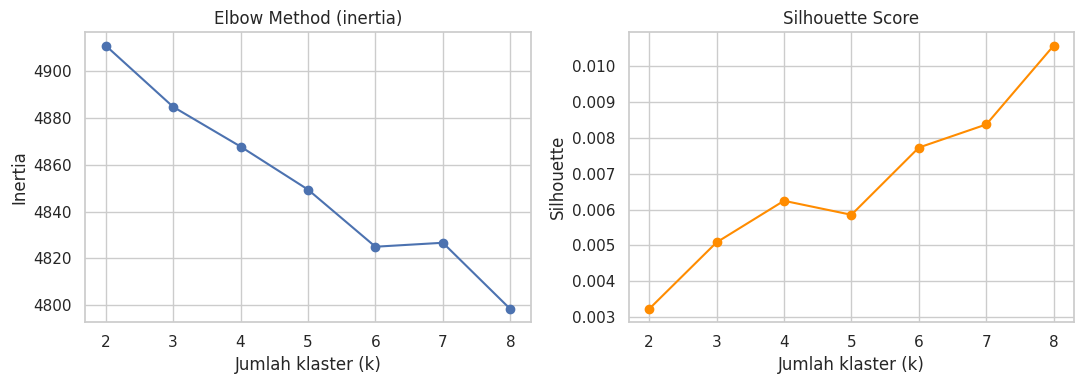

k dengan silhouette tertinggi: 8


In [52]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Ambil sampel acak 5000 dokumen agar perhitungan silhouette tidak terlalu lama
rng = np.random.RandomState(0)
idx = rng.choice(X_tfidf.shape[0], size=5000, replace=False)
X_sub = X_tfidf[idx]

ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=0, n_init=10).fit(X_sub)
    inertia.append(km.inertia_)                              # untuk elbow method
    silhouette.append(silhouette_score(X_sub, km.labels_))   # untuk silhouette method

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inertia, marker='o')
ax[0].set_title('Elbow Method (inertia)')
ax[0].set_xlabel('Jumlah klaster (k)')
ax[0].set_ylabel('Inertia')
ax[1].plot(list(ks), silhouette, marker='o', color='darkorange')
ax[1].set_title('Silhouette Score')
ax[1].set_xlabel('Jumlah klaster (k)')
ax[1].set_ylabel('Silhouette')
plt.tight_layout()
plt.show()

print("k dengan silhouette tertinggi:", list(ks)[int(np.argmax(silhouette))])

**Pembacaan hasil.** Pada grafik kiri, *k* dipilih di titik siku. Pada grafik kanan, *k* dipilih pada nilai silhouette tertinggi. Jika kedua metode menunjuk nilai berbeda, hasil dibaca bersama dengan melihat isi tiap klaster. Pada data TF-IDF berdimensi tinggi, nilai silhouette cenderung kecil (jauh di bawah 1), dan itu wajar untuk data teks.

---
**Catatan:** seluruh kode dijalankan dengan Python 3 menggunakan Pandas, NLTK, Gensim, Scikit-learn, Matplotlib, Seaborn, dan WordCloud. Dataset dan artikel dilampirkan di repositori GitHub yang tautannya tertera di bagian atas notebook.